# AWS RDS 

## ClassicModels Database

- Amazon RDS (Relational Database Service) is a **fully managed relational database** service that supports MySQL, PostgreSQL, MariaDB, Oracle, and SQL Server.

- This notebook connects to a **standard RDS MySQL** instance on the **free tier** using the `pymysql` driver — a direct TCP connection on port 3306.

- You will need your RDS **endpoint hostname**, **master username**, **password**, and the name of the target database (`classicmodels`).

- The notebook uses the **classicmodels** sample database (orders, customers, products, employees) to demonstrate typical query patterns.

https://pymysql.readthedocs.io/en/latest/


In [1]:
import boto3
import pandas as pd
import json

import pymysql
import pymysql.cursors


## Connection


In [2]:
session = boto3.Session(profile_name='ashish')
credentials = session.get_credentials()

aws_access_key_id     = credentials.access_key
aws_secret_access_key = credentials.secret_key
region_name           = 'us-east-1'


In [3]:
# -----------------------------------------------------------------------
# RDS MySQL connection details
# Replace these with your own RDS instance values.
# -----------------------------------------------------------------------

# RDS endpoint  (console → RDS → Databases → your instance → Connectivity → Endpoint)
DB_HOST     = "database-1.cvkgi402g6iv.us-east-1.rds.amazonaws.com"
DB_PORT     = 3306
DB_USER     = "admin"           # master username set when you created the instance
DB_PASSWORD = "dzYNcYDfTI2hgz4FR6F3"   # store in Secrets Manager or an env var in production
DB_NAME     = "classicmodels"


In [4]:
conn = pymysql.connect(
    host=DB_HOST,
    port=DB_PORT,
    user=DB_USER,
    password=DB_PASSWORD,
    database=DB_NAME,
    cursorclass=pymysql.cursors.DictCursor,
    autocommit=True,
)

print(f"Connected to {DB_HOST}/{DB_NAME}")


Connected to database-1.cvkgi402g6iv.us-east-1.rds.amazonaws.com/classicmodels


## Helper – run_query

A small wrapper around `pymysql`'s cursor that:
1. Executes SQL (with optional `%s` positional parameters to prevent SQL injection)
2. Fetches all rows as dicts (thanks to `DictCursor`)
3. Returns a **pandas DataFrame**


In [5]:
def run_query(sql: str, params=None) -> pd.DataFrame:
    """Execute SQL via pymysql and return a DataFrame."""
    with conn.cursor() as cur:
        cur.execute(sql, params or ())
        rows = cur.fetchall()
    return pd.DataFrame(rows)


## 1 – List all databases on this RDS instance


In [6]:
df_databases = run_query("SHOW DATABASES")
df_databases


,Database
0,classicmodels
1,information_schema
2,mysql
3,performance_schema
4,sys


## 2 – List tables in classicmodels


In [7]:
df_tables = run_query("SHOW TABLES")
df_tables


,Tables_in_classicmodels
0,customers
1,employees
2,offices
3,orderdetails
4,orders
5,payments
6,productlines
7,products


## 3 – SELECT – Browse customers

`LIMIT` keeps early exploration fast. pymysql uses `%s` positional placeholders.


In [8]:
df_customers = run_query("""
    SELECT customerNumber, customerName, city, country, creditLimit
    FROM   customers
    ORDER  BY creditLimit DESC
    LIMIT  20
""")
df_customers


,customerNumber,customerName,city,country,creditLimit
0,141,Euro+ Shopping Channel,Madrid,Spain,227600.00
1,124,Mini Gifts Distributors Ltd.,San Rafael,USA,210500.00
2,298,"Vida Sport, Ltd",Genève,Switzerland,141300.00
3,151,Muscle Machine Inc,NYC,USA,138500.00
4,187,"AV Stores, Co.",Manchester,UK,136800.00
5,146,"Saveley & Henriot, Co.",Lyon,France,123900.00
6,286,Marta's Replicas Co.,Cambridge,USA,123700.00
7,386,L'ordine Souveniers,Reggio Emilia,Italy,121400.00
8,227,Heintze Collectables,Århus,Denmark,120800.00
9,259,"Toms Spezialitäten, Ltd",Köln,Germany,120400.00


## 4 – Parameterised query – look up a single customer

pymysql uses `%s` placeholders; values are passed as a tuple to prevent SQL injection.


In [9]:
customer_id = 103   # change to any customerNumber

df_single = run_query(
    "SELECT * FROM customers WHERE customerNumber = %s",
    (customer_id,),
)
df_single


,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,103,Atelier graphique,Schmitt,Carine,40.32.2555,"54, rue Royale",None,Nantes,None,44000,France,1370,100000.00


## 5 – JOIN – Orders with customer names


In [10]:
df_orders = run_query("""
    SELECT  o.orderNumber,
            o.orderDate,
            o.requiredDate,
            o.shippedDate,
            o.status,
            c.customerName,
            c.country
    FROM    orders    o
    JOIN    customers c USING (customerNumber)
    ORDER   BY o.orderDate DESC
    LIMIT   25
""")
df_orders


,orderNumber,orderDate,requiredDate,shippedDate,status,customerName,country
0,10207,2016-12-09,2016-12-17,2016-12-11,Shipped,Diecast Collectables,USA
1,10206,2016-12-05,2016-12-13,2016-12-08,Shipped,Canadian Gift Exchange Network,Canada
2,10205,2016-12-03,2016-12-09,2016-12-07,Shipped,Euro+ Shopping Channel,Spain
3,10202,2016-12-02,2016-12-09,2016-12-06,Shipped,GiftsForHim.com,New Zealand
4,10203,2016-12-02,2016-12-11,2016-12-07,Shipped,Euro+ Shopping Channel,Spain
5,10204,2016-12-02,2016-12-10,2016-12-04,Shipped,Muscle Machine Inc,USA
6,10199,2016-12-01,2016-12-10,2016-12-06,Shipped,West Coast Collectables Co.,USA
7,10200,2016-12-01,2016-12-09,2016-12-06,Shipped,"King Kong Collectables, Co.",Hong Kong
8,10201,2016-12-01,2016-12-11,2016-12-02,Shipped,Mini Wheels Co.,USA
9,10198,2016-11-27,2016-12-06,2016-12-03,Shipped,Cruz & Sons Co.,Philippines


## 6 – Multi-table JOIN – Order line items with product details


In [11]:
order_number = 10100   # change to any orderNumber

df_line_items = run_query(
    """
    SELECT  od.orderNumber,
            od.orderLineNumber,
            p.productName,
            p.productLine,
            od.quantityOrdered,
            od.priceEach,
            ROUND(od.quantityOrdered * od.priceEach, 2) AS lineTotal
    FROM    orderdetails od
    JOIN    products     p  USING (productCode)
    WHERE   od.orderNumber = %s
    ORDER   BY od.orderLineNumber
    """,
    (order_number,),
)
df_line_items


,orderNumber,orderLineNumber,productName,productLine,quantityOrdered,priceEach,lineTotal
0,10100,1,1936 Mercedes Benz 500k Roadster,Vintage Cars,49,35.29,1729.21
1,10100,2,1911 Ford Town Car,Vintage Cars,50,55.09,2754.50
2,10100,3,1917 Grand Touring Sedan,Vintage Cars,30,136.00,4080.00
3,10100,4,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,22,75.46,1660.12


## 7 – Aggregation – Revenue by product line


In [12]:
df_revenue = run_query("""
    SELECT  p.productLine,
            COUNT(DISTINCT od.orderNumber)                    AS totalOrders,
            SUM(od.quantityOrdered)                           AS totalUnits,
            ROUND(SUM(od.quantityOrdered * od.priceEach), 2)  AS totalRevenue
    FROM    orderdetails od
    JOIN    products     p  USING (productCode)
    GROUP   BY p.productLine
    ORDER   BY totalRevenue DESC
""")
df_revenue


,productLine,totalOrders,totalUnits,totalRevenue
0,Classic Cars,209,35582,3853922.49
1,Vintage Cars,187,22933,1797559.63
2,Motorcycles,79,12778,1121426.12
3,Trucks and Buses,75,11001,1024113.57
4,Planes,66,11872,954637.54
5,Ships,68,8532,663998.34
6,Trains,47,2818,188532.92


<Axes: title={'center': 'Revenue by Product Line'}, ylabel='productLine'>

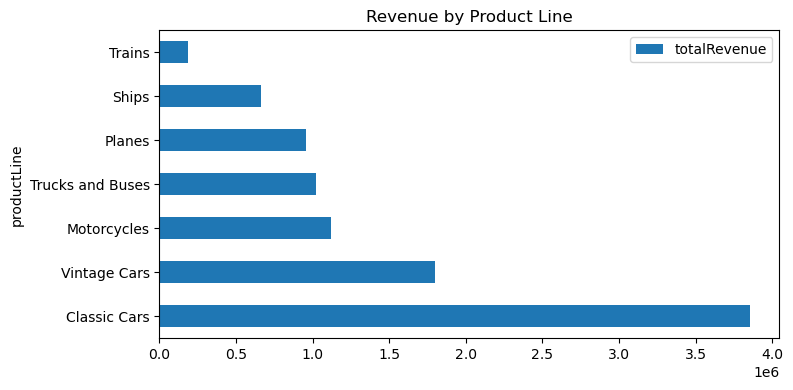

In [13]:
df_revenue['totalRevenue'] = df_revenue['totalRevenue'].astype(float)
df_revenue.set_index('productLine')[['totalRevenue']].plot(
    kind='barh', figsize=(8, 4), title='Revenue by Product Line'
)


## 8 – Subquery – Customers with no orders


In [14]:
df_no_orders = run_query("""
    SELECT  c.customerNumber, c.customerName, c.country, c.creditLimit
    FROM    customers c
    LEFT JOIN orders  o USING (customerNumber)
    WHERE   o.orderNumber IS NULL
    ORDER   BY c.customerName
""")
print(f"{len(df_no_orders)} customers with no orders")
df_no_orders


24 customers with no orders


,customerNumber,customerName,country,creditLimit
0,168,American Souvenirs Inc,USA,0.00
1,237,ANG Resellers,Spain,0.00
2,465,"Anton Designs, Ltd.",Spain,0.00
3,206,"Asian Shopping Network, Co",Singapore,0.00
4,348,"Asian Treasures, Inc.",Ireland,0.00
5,293,BG&E Collectables,Switzerland,0.00
6,335,"Cramer Spezialitäten, Ltd",Germany,0.00
7,307,Der Hund Imports,Germany,0.00
8,443,"Feuer Online Stores, Inc",Germany,0.00
9,273,"Franken Gifts, Co",Germany,0.00


## 9 – Top 10 best-selling products


In [15]:
df_top_products = run_query("""
    SELECT  p.productCode,
            p.productName,
            p.productLine,
            SUM(od.quantityOrdered)                           AS totalUnitsSold,
            ROUND(SUM(od.quantityOrdered * od.priceEach), 2)  AS totalRevenue
    FROM    orderdetails od
    JOIN    products     p  USING (productCode)
    GROUP   BY p.productCode, p.productName, p.productLine
    ORDER   BY totalUnitsSold DESC
    LIMIT   10
""")
df_top_products


,productCode,productName,productLine,totalUnitsSold,totalRevenue
0,S18_3232,1992 Ferrari 360 Spider red,Classic Cars,1808,276839.98
1,S18_1342,1937 Lincoln Berline,Vintage Cars,1111,102563.52
2,S700_4002,American Airlines: MD-11S,Planes,1085,71753.93
3,S18_3856,1941 Chevrolet Special Deluxe Cabriolet,Vintage Cars,1076,102537.45
4,S50_1341,1930 Buick Marquette Phaeton,Vintage Cars,1074,41599.24
5,S18_4600,1940s Ford truck,Trucks and Buses,1061,114232.79
6,S10_1678,1969 Harley Davidson Ultimate Chopper,Motorcycles,1057,90157.77
7,S12_4473,1957 Chevy Pickup,Trucks and Buses,1056,109946.21
8,S18_2319,1964 Mercedes Tour Bus,Trucks and Buses,1053,117669.66
9,S24_3856,1956 Porsche 356A Coupe,Classic Cars,1052,134240.71


## 10 – DML – Update a customer's credit limit

`run_query` works for DML too. `conn.affected_rows()` (or the cursor's `rowcount`) confirms how many rows changed.


In [16]:
new_limit   = 100000.00
target_id   = 103

with conn.cursor() as cur:
    cur.execute(
        "UPDATE customers SET creditLimit = %s WHERE customerNumber = %s",
        (new_limit, target_id),
    )
    print(f"Rows updated: {cur.rowcount}")

# Verify
run_query("SELECT customerNumber, customerName, creditLimit FROM customers WHERE customerNumber = %s", (target_id,))


Rows updated: 0


,customerNumber,customerName,creditLimit
0,103,Atelier graphique,100000.00


## 11 – Close the connection


In [17]:
conn.close()
print("Connection closed.")


Connection closed.
